<a href="https://colab.research.google.com/github/Group-9-AI-ML-class-A/Diabetes-Risk-screener/blob/main/Group_9_balanced_diabetic_risk_screener.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix

In [ ]:
#This line will read/capture the data from it source
df=pd.read_csv("diabetic risk data for grp 9.csv")

In [ ]:
#To view the number of rows and columns
df.shape

(15000, 19)

In [ ]:
df.head()  #To dis[lay the first five rows]

,patient_id,age,gender,city,bmi,family_history_diabetes,physical_activity_level,diet_type,smoking_status,alcohol_consumption,hours_sleep_per_night,stress_level,fasting_blood_sugar,hba1c_level,blood_pressure_systolic,blood_pressure_diastolic,waist_circumference_cm,income_bracket,diabetes_risk
0,1,47,Female,Mumbai,26.5,Yes,Sedentary,Vegetarian,Never,Never,9.0,8,178,7.3,146,90,107.1,High,Low
1,2,53,Female,Mumbai,20.5,Yes,Moderate,Vegetarian,Never,Never,7.0,6,152,6.9,156,100,93.8,Low,Low
2,3,47,Male,Thane,31.3,No,Moderate,Non-Vegetarian,Current,Regular,7.0,7,168,6.6,150,102,113.5,Low,High
3,4,41,Male,Bengaluru,22.8,No,Sedentary,Non-Vegetarian,Never,Never,9.0,5,155,6.7,126,92,109.6,Middle,Low
4,5,57,Female,Bengaluru,16.7,No,Sedentary,Non-Vegetarian,Current,Occasional,6.5,10,188,6.7,130,90,80.8,High,Low


In [ ]:
df.tail() #To dis[lay the last five rows]

,patient_id,age,gender,city,bmi,family_history_diabetes,physical_activity_level,diet_type,smoking_status,alcohol_consumption,hours_sleep_per_night,stress_level,fasting_blood_sugar,hba1c_level,blood_pressure_systolic,blood_pressure_diastolic,waist_circumference_cm,income_bracket,diabetes_risk
14995,14996,47,Male,Mumbai,37.7,No,Sedentary,Non-Vegetarian,Never,Never,6.8,7,213,8.1,150,100,141.7,High,High
14996,14997,48,Female,Mumbai,20.6,No,Moderate,Non-Vegetarian,Never,NaN,6.0,8,162,6.5,132,80,91.0,NaN,Low
14997,14998,34,Female,Nagpur,17.9,No,Active,Vegetarian,Never,Never,7.0,6,137,6.5,136,90,88.8,Low,Low
14998,14999,56,Male,Ahmedabad,20.7,Yes,Active,Vegetarian,Never,Never,6.0,5,163,6.9,140,87,94.8,Low,Low
14999,15000,54,Male,Surat,34.5,No,Moderate,Vegetarian,Never,Never,7.4,2,186,7.2,150,88,130.4,Middle,Moderate


In [ ]:
#To give information about the Data in  the Dataframe
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 19 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   patient_id                15000 non-null  int64  
 1   age                       15000 non-null  int64  
 2   gender                    15000 non-null  object 
 3   city                      15000 non-null  object 
 4   bmi                       15000 non-null  float64
 5   family_history_diabetes   15000 non-null  object 
 6   physical_activity_level   15000 non-null  object 
 7   diet_type                 15000 non-null  object 
 8   smoking_status            14528 non-null  object 
 9   alcohol_consumption       11212 non-null  object 
 10  hours_sleep_per_night     15000 non-null  float64
 11  stress_level              15000 non-null  int64  
 12  fasting_blood_sugar       15000 non-null  int64  
 13  hba1c_level               15000 non-null  float64
 14  blood_

In [ ]:
#To give comprehensive details about the column statistical information
df.describe()

,patient_id,age,bmi,hours_sleep_per_night,stress_level,fasting_blood_sugar,hba1c_level,blood_pressure_systolic,blood_pressure_diastolic,waist_circumference_cm
count,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000
mean,7500.500000,44.333667,23.062260,7.309860,5.941200,168.789933,6.878387,139.496200,86.256933,100.207933
std,4330.271354,10.383753,4.046391,1.109372,2.148406,38.365822,0.843276,12.660785,8.386529,10.760331
min,1.000000,18.000000,15.000000,3.000000,1.000000,72.000000,4.800000,80.000000,50.000000,73.200000
25%,3750.750000,38.000000,20.100000,6.700000,4.000000,145.000000,6.300000,130.000000,80.000000,92.500000
50%,7500.500000,45.000000,22.700000,7.000000,6.000000,165.000000,6.800000,140.000000,88.000000,99.300000
75%,11250.250000,52.000000,25.600000,8.000000,7.000000,189.000000,7.300000,150.000000,90.000000,106.900000
max,15000.000000,80.000000,40.800000,12.000000,10.000000,400.000000,13.400000,200.000000,120.000000,148.200000


In [ ]:
#To check for missing value within the Dataframe
df.isnull().sum()

,0
patient_id,0
age,0
gender,0
city,0
bmi,0
family_history_diabetes,0
physical_activity_level,0
diet_type,0
smoking_status,472
alcohol_consumption,3788


In [ ]:
#false shows there is no missing value while True confirm cells will missing values
df.isnull()

,patient_id,age,gender,city,bmi,family_history_diabetes,physical_activity_level,diet_type,smoking_status,alcohol_consumption,hours_sleep_per_night,stress_level,fasting_blood_sugar,hba1c_level,blood_pressure_systolic,blood_pressure_diastolic,waist_circumference_cm,income_bracket,diabetes_risk
0,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14995,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
14996,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,True,False
14997,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
14998,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False


In [ ]:
#To check for duplicates
df.duplicated().sum()

np.int64(0)

In [ ]:
#for Non-numerical value, Mode is used to fill the missing data
df['smoking_status'] = df['smoking_status'].fillna(df['smoking_status'].mode()[0])

In [ ]:
df.isnull().sum() #To further check for missing value within the Dataframe

,0
patient_id,0
age,0
gender,0
city,0
bmi,0
family_history_diabetes,0
physical_activity_level,0
diet_type,0
smoking_status,0
alcohol_consumption,3788


In [ ]:
#Unknown is used to fill the missing data
df['alcohol_consumption'] = df['alcohol_consumption'].fillna('Unknown')

In [ ]:
df.isnull().sum() #To confirm the missing column features fix

,0
patient_id,0
age,0
gender,0
city,0
bmi,0
family_history_diabetes,0
physical_activity_level,0
diet_type,0
smoking_status,0
alcohol_consumption,0


In [ ]:
 #To confirm the first and last five(5) rows again
df

,patient_id,age,gender,city,bmi,family_history_diabetes,physical_activity_level,diet_type,smoking_status,alcohol_consumption,hours_sleep_per_night,stress_level,fasting_blood_sugar,hba1c_level,blood_pressure_systolic,blood_pressure_diastolic,waist_circumference_cm,income_bracket,diabetes_risk
0,1,47,Female,Mumbai,26.5,Yes,Sedentary,Vegetarian,Never,Never,9.0,8,178,7.3,146,90,107.1,High,Low
1,2,53,Female,Mumbai,20.5,Yes,Moderate,Vegetarian,Never,Never,7.0,6,152,6.9,156,100,93.8,Low,Low
2,3,47,Male,Thane,31.3,No,Moderate,Non-Vegetarian,Current,Regular,7.0,7,168,6.6,150,102,113.5,Low,High
3,4,41,Male,Bengaluru,22.8,No,Sedentary,Non-Vegetarian,Never,Never,9.0,5,155,6.7,126,92,109.6,Middle,Low
4,5,57,Female,Bengaluru,16.7,No,Sedentary,Non-Vegetarian,Current,Occasional,6.5,10,188,6.7,130,90,80.8,High,Low
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14995,14996,47,Male,Mumbai,37.7,No,Sedentary,Non-Vegetarian,Never,Never,6.8,7,213,8.1,150,100,141.7,High,High
14996,14997,48,Female,Mumbai,20.6,No,Moderate,Non-Vegetarian,Never,Unknown,6.0,8,162,6.5,132,80,91.0,NaN,Low
14997,14998,34,Female,Nagpur,17.9,No,Active,Vegetarian,Never,Never,7.0,6,137,6.5,136,90,88.8,Low,Low
14998,14999,56,Male,Ahmedabad,20.7,Yes,Active,Vegetarian,Never,Never,6.0,5,163,6.9,140,87,94.8,Low,Low


In [ ]:
#drop columns that won't be necessry to train the model
df = df.drop(columns=['patient_id', 'city', 'income_bracket'], errors='ignore')
X = df.drop(columns=['diabetes_risk'], errors='ignore')
#drop diabetes risk in X and assign it to Y
y = df['diabetes_risk']
print(X.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 15 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   age                       15000 non-null  int64  
 1   gender                    15000 non-null  object 
 2   bmi                       15000 non-null  float64
 3   family_history_diabetes   15000 non-null  object 
 4   physical_activity_level   15000 non-null  object 
 5   diet_type                 15000 non-null  object 
 6   smoking_status            15000 non-null  object 
 7   alcohol_consumption       15000 non-null  object 
 8   hours_sleep_per_night     15000 non-null  float64
 9   stress_level              15000 non-null  int64  
 10  fasting_blood_sugar       15000 non-null  int64  
 11  hba1c_level               15000 non-null  float64
 12  blood_pressure_systolic   15000 non-null  int64  
 13  blood_pressure_diastolic  15000 non-null  int64  
 14  waist_

In [ ]:
pd.crosstab(pd.cut(df['hba1c_level'], [0, 5.7, 6.5, 20]), df['diabetes_risk'])

diabetes_risk,High,Low,Moderate
hba1c_level,,,
"(0.0, 5.7]",0,1067,0
"(5.7, 6.5]",6,4106,297
"(6.5, 20.0]",2244,3827,3453


In [ ]:
df = df.drop(columns=['fasting_blood_sugar', 'hba1c_level'], errors='ignore')
X = df.drop(columns=['diabetes_risk'], errors='ignore')

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 14 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   age                       15000 non-null  int64  
 1   gender                    15000 non-null  object 
 2   bmi                       15000 non-null  float64
 3   family_history_diabetes   15000 non-null  object 
 4   physical_activity_level   15000 non-null  object 
 5   diet_type                 15000 non-null  object 
 6   smoking_status            15000 non-null  object 
 7   alcohol_consumption       15000 non-null  object 
 8   hours_sleep_per_night     15000 non-null  float64
 9   stress_level              15000 non-null  int64  
 10  blood_pressure_systolic   15000 non-null  int64  
 11  blood_pressure_diastolic  15000 non-null  int64  
 12  waist_circumference_cm    15000 non-null  float64
 13  diabetes_risk             15000 non-null  object 
dtypes: flo

In [ ]:
#
X_encoded = pd.get_dummies(X, drop_first=True)
print(X_encoded.head())


   age   bmi  hours_sleep_per_night  stress_level  blood_pressure_systolic  \
0   47  26.5                    9.0             8                      146   
1   53  20.5                    7.0             6                      156   
2   47  31.3                    7.0             7                      150   
3   41  22.8                    9.0             5                      126   
4   57  16.7                    6.5            10                      130   

   blood_pressure_diastolic  waist_circumference_cm  gender_Male  \
0                        90                   107.1        False   
1                       100                    93.8        False   
2                       102                   113.5         True   
3                        92                   109.6         True   
4                        90                    80.8        False   

   gender_Other  family_history_diabetes_Yes  \
0         False                         True   
1         False           

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X_encoded, y, test_size=0.2, random_state=42)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
print(f"Training data shape: {X_train_scaled.shape}")
print(f"Testing data shape: {X_test_scaled.shape}")


Training data shape: (12000, 20)
Testing data shape: (3000, 20)


In [ ]:
print(X_train.columns.tolist())

['age', 'bmi', 'hours_sleep_per_night', 'stress_level', 'blood_pressure_systolic', 'blood_pressure_diastolic', 'waist_circumference_cm', 'gender_Male', 'gender_Other', 'family_history_diabetes_Yes', 'physical_activity_level_Moderate', 'physical_activity_level_Sedentary', 'diet_type_Pescatarian', 'diet_type_Vegan', 'diet_type_Vegetarian', 'smoking_status_Former', 'smoking_status_Never', 'alcohol_consumption_Occasional', 'alcohol_consumption_Regular', 'alcohol_consumption_Unknown']


In [ ]:
rf_model = RandomForestClassifier(n_estimators=100, random_state=42, class_weight='balanced')
rf_model.fit(X_train_scaled, y_train)
y_pred = rf_model.predict(X_test_scaled)

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Confusion Matrix:
[[  59  275   98]
 [  32 1687  100]
 [  42  580  127]]


In [ ]:
#
print("\nClassification Report:")
print(classification_report(y_test, y_pred))


Classification Report:
              precision    recall  f1-score   support

        High       0.44      0.14      0.21       432
         Low       0.66      0.93      0.77      1819
    Moderate       0.39      0.17      0.24       749

    accuracy                           0.62      3000
   macro avg       0.50      0.41      0.41      3000
weighted avg       0.56      0.62      0.56      3000



In [ ]:
from imblearn.over_sampling import SMOTE
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train_scaled, y_train)
print("Old training target counts:")
print(y_train.value_counts())
print("\nNew SMOTE training target counts:")
print(y_train_smote.value_counts())
rf_smote = RandomForestClassifier(n_estimators=100, random_state=42)
rf_smote.fit(X_train_smote, y_train_smote)
y_pred_smote = rf_smote.predict(X_test_scaled)

print("\n--- SMOTE Evaluation ---")
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_smote))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_smote))

Old training target counts:
diabetes_risk
Low         7181
Moderate    3001
High        1818
Name: count, dtype: int64

New SMOTE training target counts:
diabetes_risk
Low         7181
Moderate    7181
High        7181
Name: count, dtype: int64

--- SMOTE Evaluation ---
Confusion Matrix:
[[ 113  180  139]
 [ 123 1440  256]
 [ 142  394  213]]

Classification Report:
              precision    recall  f1-score   support

        High       0.30      0.26      0.28       432
         Low       0.71      0.79      0.75      1819
    Moderate       0.35      0.28      0.31       749

    accuracy                           0.59      3000
   macro avg       0.45      0.45      0.45      3000
weighted avg       0.56      0.59      0.57      3000



In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
importances = rf_smote.feature_importances_
feature_importance_df = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)
print("Top 10 Clinical Risk Factors:")
print(feature_importance_df.head(10))

Top 10 Clinical Risk Factors:
                        Feature  Importance
0                           age    0.139379
1                           bmi    0.121578
6        waist_circumference_cm    0.117449
4       blood_pressure_systolic    0.104909
5      blood_pressure_diastolic    0.100529
3                  stress_level    0.100403
2         hours_sleep_per_night    0.094069
9   family_history_diabetes_Yes    0.030262
14         diet_type_Vegetarian    0.027389
7                   gender_Male    0.026707


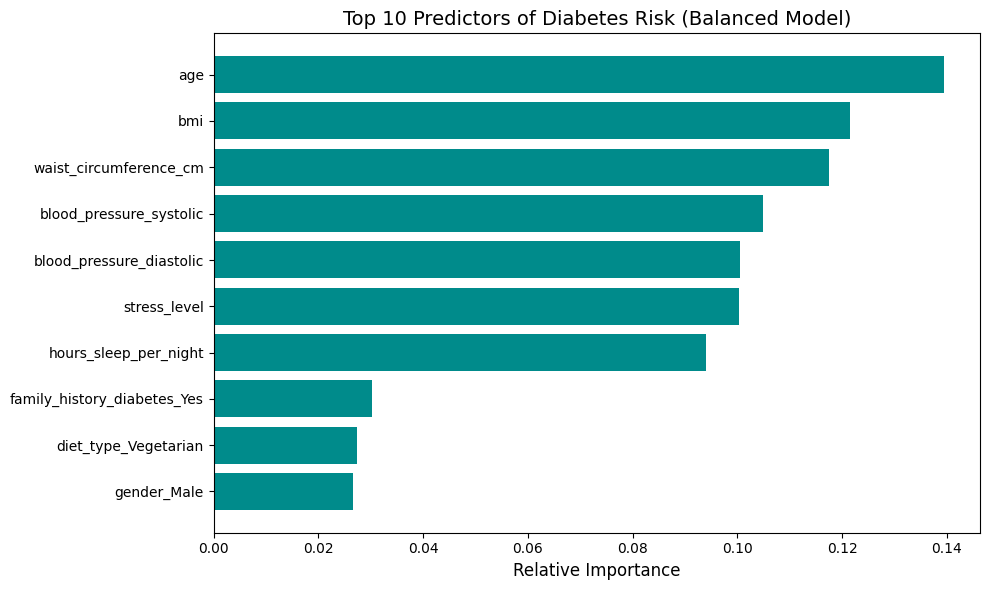

In [ ]:
plt.figure(figsize=(10, 6))
plt.barh(feature_importance_df['Feature'][:10][::-1], feature_importance_df['Importance'][:10][::-1], color='darkcyan')
plt.title('Top 10 Predictors of Diabetes Risk (Balanced Model)', fontsize=14)
plt.xlabel('Relative Importance', fontsize=12)
plt.tight_layout()
plt.show()

In [ ]:
import joblib
joblib.dump(rf_smote, 'diabetes_risk_model.pkl')
joblib.dump(scaler, 'diabetes_scaler.pkl')
print("Model and scaler successfully exported for deployment!")


Model and scaler successfully exported for deployment!


In [ ]:
import sklearn, numpy, pandas
print("scikit-learn==" + sklearn.__version__)
print("numpy==" + numpy.__version__)
print("pandas==" + pandas.__version__)

scikit-learn==1.6.1
numpy==2.1.3
pandas==2.2.3
